# RMN original frente a RMN int8
Checkpoint original: `benchmarks/resmasking_net`, asociado al 74,14 % publicado en FER2013.
Esta prueba usa nuestra validación, con posible solapamiento y **sin TTA**. No reproduce el benchmark.
Ambos reciben exactamente el mismo tensor: rostro gris 224×224, tres canales idénticos, /255.
Se mantienen siete salidas y las predicciones de miedo cuentan como error para las otras seis.
Usa el kernel `.venv` del proyecto. Los modelos y programas anteriores se conservan.


In [1]:
from comparar_rmn import ComparadorRMN
comparador = ComparadorRMN()
print('Original verificado y cargado; int8 cargado. CPU, 4 hilos por motor.')
print('Metadatos del checkpoint original:', comparador.metadata_checkpoint)


Original verificado y cargado; int8 cargado. CPU, 4 hilos por motor.
Metadatos del checkpoint original: {'data_path': 'saved/data/fer2013', 'image_size': 224, 'in_channels': 3, 'num_classes': 7, 'arch': 'resmasking_dropout1', 'lr': 0.0001, 'momentum': 0.9, 'weight_decay': 0.001, 'distributed': 0, 'batch_size': 48, 'num_workers': 8, 'device': 'cuda:0', 'max_epoch_num': 50, 'max_plateau_count': 8, 'plateau_patience': 2, 'steplr': 50, 'log_dir': 'saved/logs', 'checkpoint_dir': 'saved/checkpoints', 'model_name': 'rot30', 'cwd': '/root/tee', 'best_val_loss': 1.3742827121416727, 'best_val_acc': 70.59009236653645, 'best_train_loss': 0.13760388992067568, 'best_train_acc': 95.02643553362864, 'test_acc': 74.14321538032878}


## Comparar con las mismas imágenes
Ejecutar tarda varios minutos en CPU. No utiliza la carpeta test.

Comparación EXPLORATORIA sobre 1527 imágenes. No reproduce el benchmark de FER2013.
Salida: C:\Users\Garcia\Desktop\Neuro-IA-Marketing\resultados_preentrenados\RMN_original_vs_int8_20261014_121443_788162
original: 100/1527
original: 200/1527
original: 300/1527
original: 400/1527
original: 500/1527
original: 600/1527
original: 700/1527
original: 800/1527
original: 900/1527
original: 1000/1527
original: 1100/1527
original: 1200/1527
original: 1300/1527
original: 1400/1527
original: 1500/1527
{"version": "original", "accuracy": 0.8637851997380485, "macro_f1_seis_clases": 0.8542939982854357, "predicciones_miedo": 26, "n": 1527, "mediana_ms_cpu": 175.74779991991818}
int8: 100/1527
int8: 200/1527
int8: 300/1527
int8: 400/1527
int8: 500/1527
int8: 600/1527
int8: 700/1527
int8: 800/1527
int8: 900/1527
int8: 1000/1527
int8: 1100/1527
int8: 1200/1527
int8: 1300/1527
int8: 1400/1527
int8: 1500/1527
{"version": "int8", "accuracy": 0.5036018336607727, "macro_f1_seis_clases": 0.5083918764402373, "pr

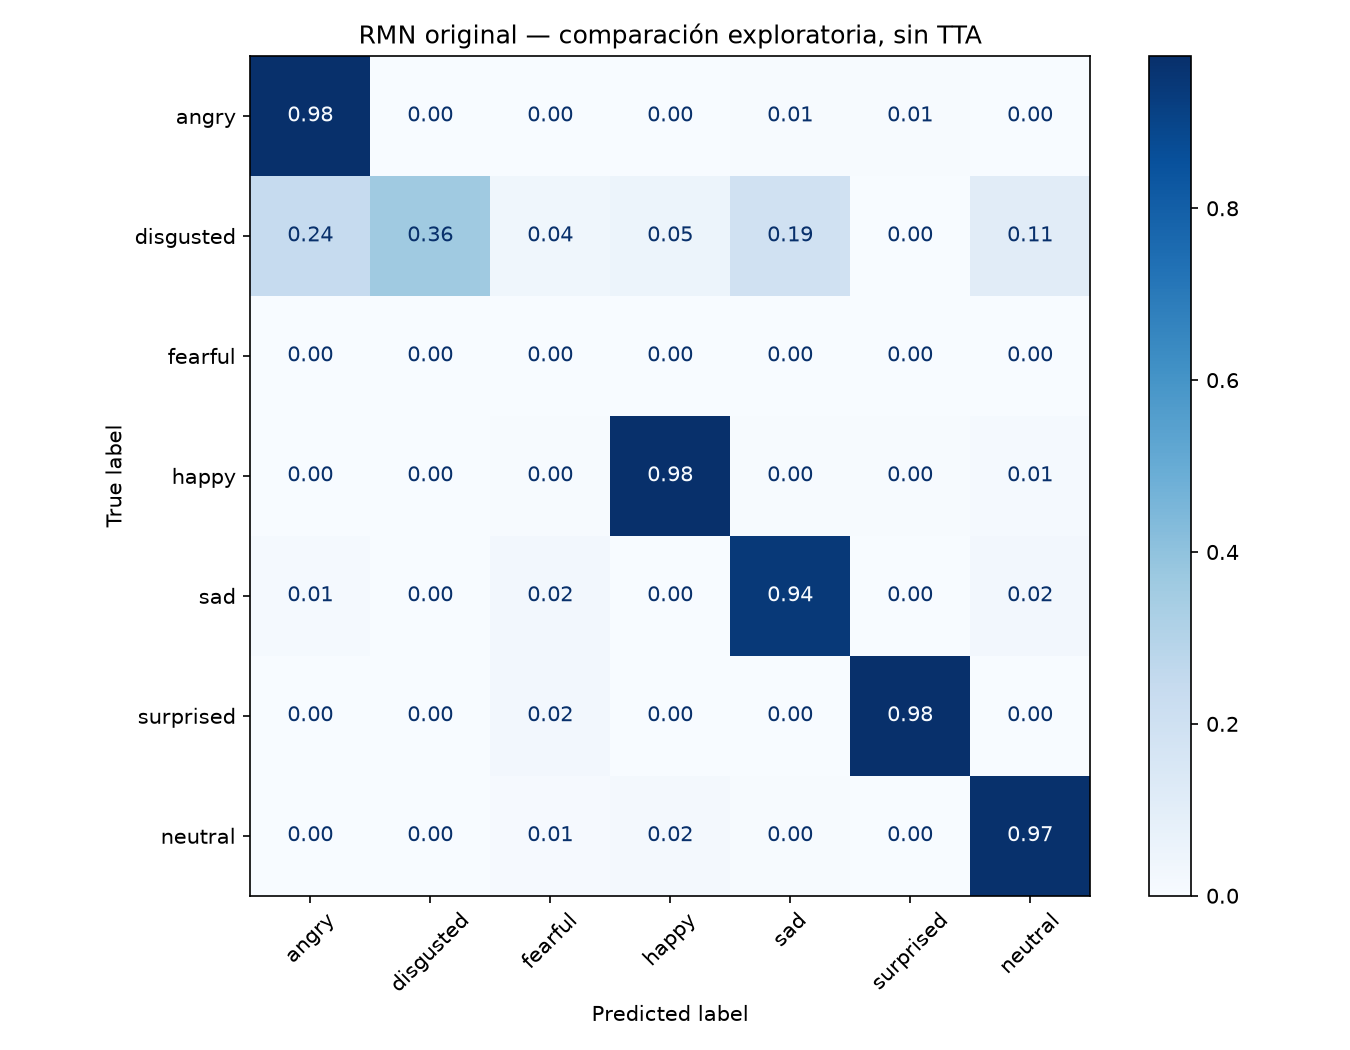

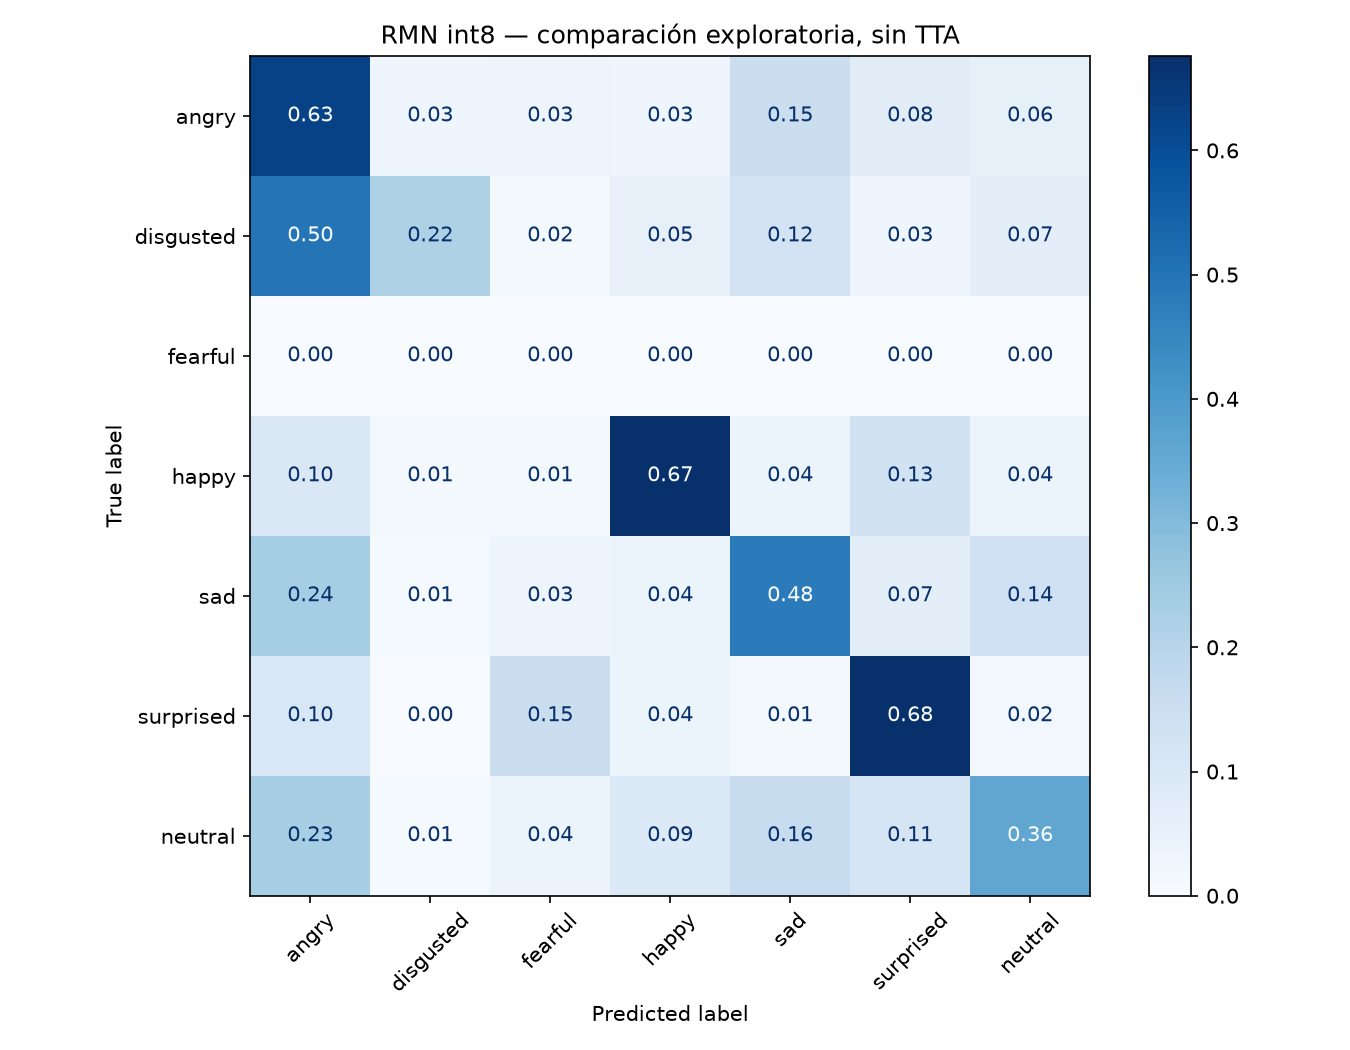

In [2]:
comparador.comparar()

## Probar una foto de un rostro ya recortado
Configura FOTO. Si quieres usar una foto completa o abrir la cámara, consulta PROBAR_RMN.md.
No se envían imágenes a servicios externos.


In [ ]:
from pathlib import Path
import cv2
import numpy as np
from comparar_rmn import ES

FOTO = None  # Ejemplo: Path('mi_rostro.jpg')
if FOTO is None:
    print('Configura FOTO con la ruta de un rostro recortado.')
else:
    rostro = cv2.imread(str(FOTO))
    if rostro is None:
        raise FileNotFoundError(FOTO)
    for version in ('original', 'int8'):
        scores = comparador.predecir(rostro, version)
        print(version, ES[int(scores.argmax())], dict(zip(ES, np.round(scores, 3).tolist())))
